<a href="https://colab.research.google.com/github/sonujose123/End-to-End-Sentiment-Analysis-ML-Project/blob/main/Sentiment_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

In [ ]:
import pandas as pd
df = pd.read_csv('amazon_alexa.tsv', delimiter='\t', quoting=3)
print(df.shape)
df.head()

(3150, 5)


,rating,date,variation,verified_reviews,feedback
0,5,31-Jul-18,Charcoal Fabric,Love my Echo!,1
1,5,31-Jul-18,Charcoal Fabric,Loved it!,1
2,4,31-Jul-18,Walnut Finish,"""Sometimes while playing a game, you can answe...",1
3,5,31-Jul-18,Charcoal Fabric,"""I have had a lot of fun with this thing. My 4...",1
4,5,31-Jul-18,Charcoal Fabric,Music,1


In [ ]:
print(df.isnull().sum())

rating              0
date                0
variation           0
verified_reviews    1
feedback            0
dtype: int64


In [ ]:
df = df.dropna(subset=['verified_reviews']).reset_index(drop=True)
print(len(df))
print(df['feedback'].value_counts())

3149
feedback
1    2893
0     256
Name: count, dtype: int64


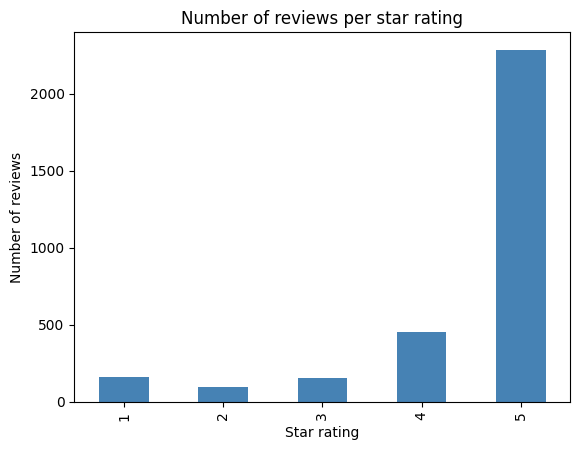

In [ ]:
import matplotlib.pyplot as plt
df['rating'].value_counts().sort_index().plot(kind='bar', color='steelblue')
plt.title('Number of reviews per star rating')
plt.xlabel('Star rating')
plt.ylabel('Number of reviews')
plt.show()


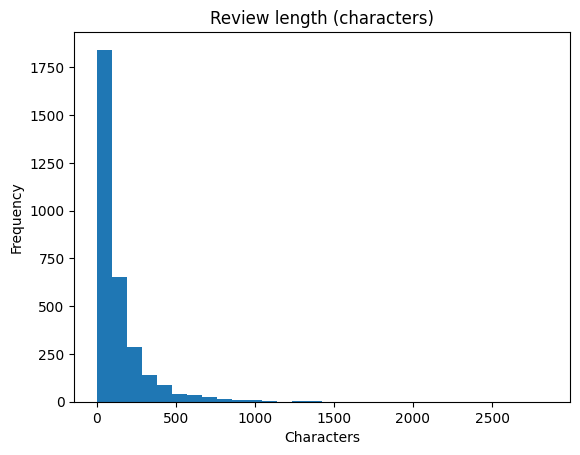

In [ ]:
df['length'] = df['verified_reviews'].str.len()
df['length'].plot(kind='hist', bins=30)
plt.title('Review length (characters)')
plt.xlabel('Characters')
plt.show()

In [ ]:
import re
sample = df['verified_reviews'][0]
print(sample)
print(re.sub('[^A-Za-z]', ' ', sample))



Love my Echo!
Love my Echo 


In [50]:
import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

nltk.download('stopwords')

STOP = set(stopwords.words('english'))
stemmer = PorterStemmer()

print(len(STOP))
print('the' in STOP, 'great' in STOP, 'not' in STOP)
print(stemmer.stem('loving'), stemmer.stem('speakers'), stemmer.stem('disappointed'))

198
True False True
love speaker disappoint


[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [51]:
NEGATIONS = {'no', 'nor', 'not', 'don', 'didn', 'doesn', 'isn', 'wasn', 'weren',
             'won', 'wouldn', 'couldn', 'shouldn', 'hasn', 'haven', 'hadn',
             'aren', 'ain', 'mustn', 'needn', 'shan', 'mightn'}

STOP = set(stopwords.words('english')) -  NEGATIONS

In [52]:
def clean_text(text):
  text = re.sub('[^a-zA-Z]', ' ', str(text))
  words = text.lower().split()
  words = [stemmer.stem(w) for w in words if w not in STOP]
  return ' '.join(words)

print(clean_text('The speakers are LOVING it!!!'))
print(clean_text('It did not work'))

speaker love
not work
